<a href="https://colab.research.google.com/github/Syeda-Maham-fatima05/Intelligent-Vacuum-Cleaning-Robot/blob/main/Student1_Environment_GBFS/Student1_Environment_GBFS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Intelligent Vacuum Cleaning Robot
## Student 1: Environment Setup and Greedy Best-First Search (GBFS)

### 1. Introduction

This notebook implements the environment setup and Greedy Best-First
Search (GBFS) algorithm for an Intelligent Vacuum Cleaning Robot.

The robot operates in a two-dimensional grid environment consisting
of free spaces, obstacles, dirty locations and a charging station.

The main objectives of this implementation are:

- Load the environment configuration from an external text file.
- Represent the environment using a grid-based structure.
- Validate the environment configuration.
- Visualize obstacles, dirty locations and the charging station.
- Implement the required environment functions.
- Implement Greedy Best-First Search using Manhattan Distance.
- Test the algorithm by finding paths to different dirty locations.

The implementation is designed to support integration with other
search algorithms and the CSP-based cleaning schedule developed
by the other group members.

### 2. Import Required Libraries

This section imports the Python libraries required for environment
configuration, search algorithm implementation and visualization.

The following libraries are used:

- ast: Parses coordinate information from the environment file.
- heapq: Implements the priority queue used in GBFS.
- itertools: Generates unique counter values for priority queue entries.
- matplotlib.pyplot: Visualizes the grid environment and search paths.
- deque: Supports queue-based traversal for reachability checking.
- Listed libraries are used to organize and simplify the implementation.

These libraries provide the basic functionality required for
environment processing, pathfinding and testing.

In [1]:
import ast
import heapq
import itertools
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from collections import deque

### 3. Environment Configuration File

The environment is defined in an external text file named
Environment.txt.

This file contains the configuration of the robot's working
environment, including:

1. Grid dimensions (number of rows and columns).
2. Total number of obstacles.
3. Coordinates of obstacle locations.
4. Total number of dirty locations.
5. Coordinates of dirty locations.
6. Coordinates of the charging station.

The environment is stored separately from the Python implementation
so that different configurations can be loaded and tested without
modifying the program code.

A sample environment file is also provided for testing and
verification purposes.

### 4. Uploading the Environment File

This section allows the user to upload Environment.txt directly
into the Google Colab environment.

The uploaded file is used as the input for the environment
loading function.

This approach makes the implementation flexible because
different environment configurations can be tested by
uploading different text files.

The uploaded filename is stored dynamically for further processing.

In [2]:
from google.colab import files

uploaded = files.upload()

filename = next(iter(uploaded.keys()))

print("Uploaded file:", filename)

Saving Environment.txt to Environment.txt
Uploaded file: Environment.txt


### 4.1 Parsing Coordinates and Loading the Environment

This section defines two functions for processing the environment file.

1. parse_coordinates():
   Converts coordinate information from the text file into
   Python tuples that can be used by the program.

2. load_environment():
   Reads the environment configuration and extracts the grid
   dimensions, obstacles, dirty locations and charging station.

The extracted information is stored in a Python dictionary
named grid.

Using a dictionary provides a structured representation of
the environment and allows different functions and search
algorithms to access the same environment information.

In [34]:
def parse_coordinates(text):
    coordinates = ast.literal_eval(text.strip())

    # Convert a single coordinate into a list
    if (
        isinstance(coordinates, tuple)
        and len(coordinates) == 2
        and all(isinstance(x, int) for x in coordinates)
    ):
        coordinates = [coordinates]

    return [tuple(point) for point in coordinates]


def load_environment(filename):

    with open(filename, "r") as file:
        lines = [line.strip() for line in file if line.strip()]

    # Read grid dimensions
    rows, cols = map(int, lines[0].split(","))

    # Read obstacle information
    obstacle_count = int(lines[1])
    obstacles = set(parse_coordinates(lines[2]))

    # Read dirty location information
    dirty_count = int(lines[3])
    dirty_locations = parse_coordinates(lines[4])

    # Read charging station
    charging_station = parse_coordinates(lines[5])[0]

    grid = {
        "rows": rows,
        "cols": cols,
        "obstacles": obstacles,
        "dirty_locations": dirty_locations,
        "charging_station": charging_station
    }

    return grid

### 4.2 Displaying the Loaded Environment Information

After loading the environment file, this section displays
the extracted configuration details.

The displayed information includes:

- Grid dimensions.
- Obstacle coordinates.
- Dirty location coordinates.
- Charging station position.

This step confirms that the environment file has been
successfully read and its information has been extracted.

In [33]:
grid = load_environment(filename)

print("Grid Size:", grid["rows"], "x", grid["cols"])
print("Obstacles:", grid["obstacles"])
print("Dirty Locations:", grid["dirty_locations"])
print("Charging Station:", grid["charging_station"])

Grid Size: 8 x 8
Obstacles: {(2, 4), (6, 5), (0, 0), (6, 1), (7, 3), (0, 5), (3, 6), (3, 2)}
Dirty Locations: [(5, 3), (4, 4), (1, 2), (6, 7)]
Charging Station: (0, 7)


### 5. Environment Validation

Environment validation ensures that the loaded grid configuration
satisfies the requirements of the vacuum cleaning robot problem.

The validation function performs several checks:

1. Verifies that the grid dimensions meet the minimum requirement.
2. Checks that the environment contains at least six obstacles.
3. Checks that at least four dirty locations are defined.
4. Detects duplicate dirty location coordinates.
5. Ensures that all coordinates are within the grid boundaries.
6. Prevents obstacles from overlapping dirty locations.
7. Ensures that the charging station does not overlap
   an obstacle or dirty location.
8. Checks whether all dirty locations are reachable from
   the charging station.

If any requirement is violated, the function displays
appropriate error messages.

If all checks are satisfied, the environment is declared valid.

In [4]:
def validate_environment(grid):

    rows = grid["rows"]
    cols = grid["cols"]
    obstacles = grid["obstacles"]
    dirty = grid["dirty_locations"]
    charging = grid["charging_station"]

    errors = []

    # Check grid dimensions
    if rows < 8 or cols < 8:
        errors.append("Grid must be at least 8x8.")

    # Check obstacle count
    if len(obstacles) < 6:
        errors.append("At least 6 obstacles are required.")

    # Check dirty locations
    if len(dirty) < 4:
        errors.append("At least 4 dirty locations are required.")

    # Check duplicate coordinates
    if len(dirty) != len(set(dirty)):
        errors.append("Duplicate dirty locations found.")

    # Check coordinate boundaries
    all_positions = obstacles | set(dirty) | {charging}

    for r, c in all_positions:
        if not (0 <= r < rows and 0 <= c < cols):
            errors.append(f"Coordinate {(r, c)} is outside the grid.")

    # Check overlapping positions
    if obstacles.intersection(dirty):
        errors.append("An obstacle overlaps a dirty location.")

    if charging in obstacles:
        errors.append("Charging station overlaps an obstacle.")

    if charging in dirty:
        errors.append("Charging station overlaps a dirty location.")

    # Check every dirty location is reachable
    for location in dirty:
        if not is_reachable(charging, location, grid):
            errors.append(f"Dirty location {location} is unreachable.")

    if errors:
        print("Environment is INVALID:")
        for error in errors:
            print("-", error)
        return False

    print("Environment is VALID!")
    return True

### 5.1 Reachability Checking

This section defines the is_reachable() function to determine
whether a particular destination can be reached from a starting
position.

Breadth-First Search (BFS) is used internally to explore the
grid and identify reachable positions.

The function uses a queue to examine neighboring cells and
a visited set to prevent repeated exploration.

Only valid neighboring positions are considered, while
obstacles and positions outside the grid are excluded.

This check ensures that the robot is not assigned a dirty
location that cannot be reached from the charging station.

In [5]:
def is_reachable(start, goal, grid):

    queue = deque([start])
    visited = {start}

    while queue:

        current = queue.popleft()

        if current == goal:
            return True

        for next_state, action, cost in get_successors(current, grid):

            if next_state not in visited:
                visited.add(next_state)
                queue.append(next_state)

    return False

### 5.2 Executing Environment Validation

After defining the environment loading and validation functions,
the environment is loaded into the grid dictionary.

The validate_environment() function is then executed to
check whether the configuration satisfies the required conditions.

The validation result is stored in environment_valid.

This variable is later used to determine whether the search
algorithm should proceed with testing.

In [11]:
grid = load_environment(filename)

print("Grid Size:", grid["rows"], "x", grid["cols"])
print("Obstacles:", grid["obstacles"])
print("Dirty Locations:", grid["dirty_locations"])
print("Charging Station:", grid["charging_station"])

Grid Size: 8 x 8
Obstacles: {(2, 4), (6, 5), (0, 0), (6, 1), (7, 3), (0, 5), (3, 6), (3, 2)}
Dirty Locations: [(5, 3), (4, 4), (1, 2), (6, 7)]
Charging Station: (0, 7)


### 6. Grid Environment Visualization

This section provides a graphical representation of the
vacuum cleaning robot's environment using Matplotlib.

Each grid cell represents a possible robot position.

Different colors and labels are used to distinguish the
environment components:

- White: Free space where the robot can move.
- Gray: Obstacle locations that block movement.
- Orange: Dirty locations that require cleaning.
- Light Green: Charging station.

The grid uses row and column coordinates to represent
the position of each cell.

Visualization makes it easier to understand the environment,
identify obstacle placement and verify the selected coordinates.

In [24]:
def display_grid(grid):

    rows = grid["rows"]
    cols = grid["cols"]

    fig, ax = plt.subplots(figsize=(8, 8))

    ax.set_xlim(0, cols)
    ax.set_ylim(rows, 0)

    # Draw grid cells
    for r in range(rows):
        for c in range(cols):

            color = "white"
            label = ""

            if (r, c) in grid["obstacles"]:
                color = "gray"
                label = "X"

            elif (r, c) in grid["dirty_locations"]:
                color = "orange"
                index = grid["dirty_locations"].index((r, c))
                label = f"D{index + 1}"

            elif (r, c) == grid["charging_station"]:
                color = "lightgreen"
                label = "C"

            rect = plt.Rectangle(
                (c, r), 1, 1,
                facecolor=color,
                edgecolor="black"
            )

            ax.add_patch(rect)

            ax.text(
                c + 0.5,
                r + 0.5,
                label,
                ha="center",
                va="center",
                fontsize=12,
                fontweight="bold"
            )

    ax.set_xticks(range(cols))
    ax.set_yticks(range(rows))
    ax.set_xticklabels(range(cols))
    ax.set_yticklabels(range(rows))

    ax.set_title("Vacuum Cleaning Robot Environment")
    ax.set_xlabel("Column")
    ax.set_ylabel("Row")

    plt.grid(False)
    plt.show()

### 6.1 Displaying the Grid Environment

The display_grid() function is called to visualize the
environment configuration.

The resulting grid provides a clear view of the robot's
starting charging station, dirty locations, obstacles
and available free spaces.

This visualization is also useful for checking whether
the environment coordinates have been represented correctly.

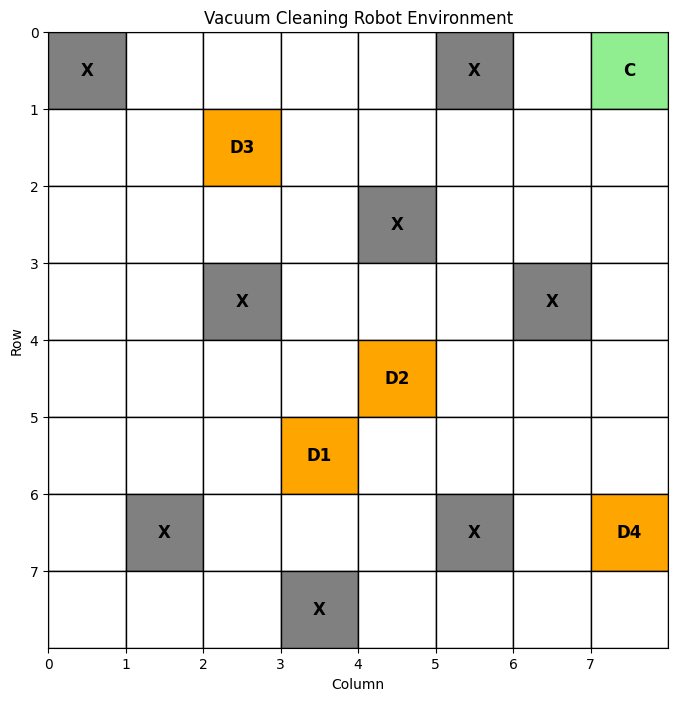

In [25]:
display_grid(grid)

### 7. Environment Functions

This section implements the fundamental functions required
for the robot's movement and search operations.

These functions provide a common interface for the different
search algorithms used in the project.

The implemented functions include:

1. get_successors():
   Generates all valid neighboring positions from the current state.

2. goal_test():
   Determines whether the current state matches the destination.

3. path_cost():
   Calculates the total movement cost of a generated path.

These functions provide the basic operations required for
searching and navigating the grid environment.

They are designed to be reusable by other search algorithms
during group integration.

### 7.1 Successor Generation Function

The get_successors() function identifies all valid movements
available to the robot from its current position.

The robot can move in four directions:

- UP
- DOWN
- LEFT
- RIGHT

Each movement has a cost of 1.

Before adding a neighboring position to the successor list,
the function checks that:

1. The new position is within the grid boundaries.
2. The new position is not an obstacle.

The function returns the valid next states along with
their corresponding movement actions and costs.

This ensures that the robot only explores legal movements.

In [26]:
def get_successors(state, grid):

    row, col = state

    moves = [
        (-1, 0, "UP"),
        (1, 0, "DOWN"),
        (0, -1, "LEFT"),
        (0, 1, "RIGHT")
    ]

    successors = []

    for dr, dc, action in moves:

        new_row = row + dr
        new_col = col + dc

        next_state = (new_row, new_col)

        # Check grid boundaries and obstacles
        if (
            0 <= new_row < grid["rows"]
            and 0 <= new_col < grid["cols"]
            and next_state not in grid["obstacles"]
        ):

            successors.append((next_state, action, 1))

    return successors

In [27]:
environment_valid = validate_environment(grid)

Environment is VALID!


### 7.2 Goal Test Function

The goal_test() function checks whether the robot has
reached its specified destination.

It compares the current state with the goal state.

If both positions are identical, the function returns True,
indicating that the destination has been reached.

Otherwise, it returns False.

This function is used by the search algorithms to determine
when the search process should terminate successfully.

In [18]:
def goal_test(state, goal_state):

    return state == goal_state

### 7.3 Path Cost Function

The path_cost() function calculates the total movement cost
of a path generated by a search algorithm.

In this environment, every valid movement between adjacent
cells has a cost of 1.

Therefore, the total path cost is calculated by counting
the number of movements performed.

The function returns zero for an empty or single-position path
because no movement is required in those cases.

In [19]:
def path_cost(path):

    if not path:
        return 0

    return len(path) - 1

In [20]:
example_path = [(0, 7), (1, 7), (1, 6), (2, 6)]

print("Path Cost:", path_cost(example_path))

Path Cost: 3


### 8. Manhattan Distance Heuristic

A heuristic function estimates the distance between the
robot's current position and its target destination.

In this implementation, Manhattan Distance is used as
the heuristic for Greedy Best-First Search.

Manhattan Distance is calculated using the absolute
difference between the row coordinates and column coordinates.

The formula is:

h(n) = |r1 - r2| + |c1 - c2|

Where:

- r1 and c1 represent the current position.
- r2 and c2 represent the goal position.

The heuristic assumes movement in four directions:
UP, DOWN, LEFT and RIGHT.

It does not consider obstacles or diagonal movements.

A smaller heuristic value indicates that the current
position is estimated to be closer to the goal.

GBFS uses this heuristic to prioritize which state
should be explored next.

### 8.1 Implementing the Manhattan Distance Function

The heuristic() function calculates the Manhattan Distance
between the current state and the goal state.

It extracts the row and column coordinates of both positions
and calculates their absolute differences.

The resulting value is returned as the estimated distance
between the two positions.

This function is used by the GBFS algorithm to prioritize
states based on their estimated distance from the goal.

In [21]:
def heuristic(state, goal_state):

    row1, col1 = state
    row2, col2 = goal_state

    return abs(row1 - row2) + abs(col1 - col2)

### 8.2 Testing the Heuristic Function

A sample test is performed to verify the Manhattan Distance
calculation.

The function receives a starting position and a goal position
and returns the estimated distance between them.

This test confirms that the heuristic function calculates
the expected distance and is ready to be used by GBFS.

In [22]:
print(heuristic((0, 7), (5, 3)))

9


### 9. Greedy Best-First Search (GBFS)

Greedy Best-First Search is an informed search algorithm that selects
the next node based on its estimated distance from the goal.

It uses a heuristic function h(n) to determine which node should
be explored first. In this implementation, Manhattan Distance is
used as the heuristic.

The algorithm maintains a priority queue to select the node with
the smallest heuristic value. It also maintains a visited set to
avoid repeatedly expanding the same state and a parent dictionary
to reconstruct the final path.

The algorithm returns:
- The path from the starting position to the goal.
- The total path cost.
- The number of nodes expanded during the search.

### 9.1 Working Principle of GBFS

The GBFS algorithm follows these steps:

1. Initialize a priority queue with the starting position.
2. Calculate the heuristic distance between the starting position
   and the goal.
3. Remove the node with the smallest heuristic value.
4. Check whether the selected node is the goal.
5. If the goal is not reached, generate all valid successor states.
6. Add unexplored successor states to the priority queue.
7. Repeat the process until the goal is reached or no valid
   path remains.
8. Reconstruct the path using the parent dictionary.

GBFS is not guaranteed to find the shortest path because it
prioritizes heuristic values rather than the accumulated path cost.

In [28]:
def greedy_best_first_search(start, goal, grid):

    # Priority queue: (heuristic, tie_breaker, state)
    priority_queue = []

    counter = itertools.count()

    heapq.heappush(
        priority_queue,
        (heuristic(start, goal), next(counter), start)
    )

    # Track visited and discovered states
    visited = set()
    discovered = {start}

    # Store parent of each state for path reconstruction
    parent = {start: None}

    nodes_expanded = 0

    while priority_queue:

        # Select the state with the smallest heuristic
        h_value, _, current = heapq.heappop(priority_queue)

        if current in visited:
            continue

        visited.add(current)

        # Check whether goal is reached
        if goal_test(current, goal):

            path = []
            state = current

            while state is not None:
                path.append(state)
                state = parent[state]

            path.reverse()

            return path, path_cost(path), nodes_expanded

        # Expand current state
        nodes_expanded += 1

        # Generate valid neighboring states
        for next_state, action, step_cost in get_successors(current, grid):

            if next_state not in discovered:

                discovered.add(next_state)

                parent[next_state] = current

                h = heuristic(next_state, goal)

                heapq.heappush(
                    priority_queue,
                    (h, next(counter), next_state)
                )

    # No path found
    return None, float("inf"), nodes_expanded

### 10. Testing the GBFS Algorithm

Before testing GBFS, the environment is validated to ensure that
the grid dimensions, obstacle coordinates, dirty locations and
charging station are correctly defined.

The validation function also checks whether all dirty locations
are reachable from the charging station.

GBFS testing is performed only when the environment is valid.

In [29]:
environment_valid = validate_environment(grid)

Environment is VALID!


### 10.1 Finding Paths to All Dirty Locations

In this test, the robot starts from the charging station and
uses Greedy Best-First Search to find a path to each dirty location.

Each dirty location is tested separately.

For every search, the program displays:
- Destination dirty location.
- Generated path.
- Total path cost.
- Number of nodes expanded.

This test verifies that GBFS can navigate around obstacles
and reach the required cleaning locations.

In [30]:
start = grid["charging_station"]

if environment_valid:

    for index, goal in enumerate(grid["dirty_locations"]):

        print(f"\nD{index + 1}: {goal}")

        path, cost, expanded = greedy_best_first_search(
            start,
            goal,
            grid
        )

        print("Path:", path)
        print("Total Cost:", cost)
        print("Nodes Expanded:", expanded)


D1: (5, 3)
Path: [(0, 7), (1, 7), (2, 7), (3, 7), (4, 7), (5, 7), (5, 6), (5, 5), (5, 4), (5, 3)]
Total Cost: 9
Nodes Expanded: 9

D2: (4, 4)
Path: [(0, 7), (1, 7), (2, 7), (3, 7), (4, 7), (4, 6), (4, 5), (4, 4)]
Total Cost: 7
Nodes Expanded: 7

D3: (1, 2)
Path: [(0, 7), (1, 7), (1, 6), (1, 5), (1, 4), (1, 3), (1, 2)]
Total Cost: 6
Nodes Expanded: 6

D4: (6, 7)
Path: [(0, 7), (1, 7), (2, 7), (3, 7), (4, 7), (5, 7), (6, 7)]
Total Cost: 6
Nodes Expanded: 6


### 10.2 Visualization of the GBFS Path

This section visualizes the path generated by GBFS on the grid.

The visualization highlights the starting position, destination,
obstacles, dirty locations and the path followed by the robot.

It helps verify that the robot follows valid movements without
crossing obstacles or leaving the grid boundaries.

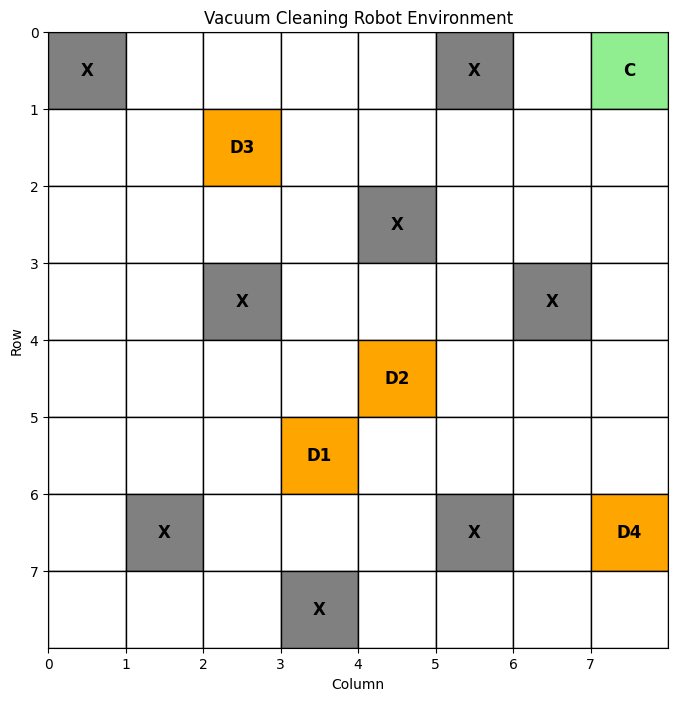

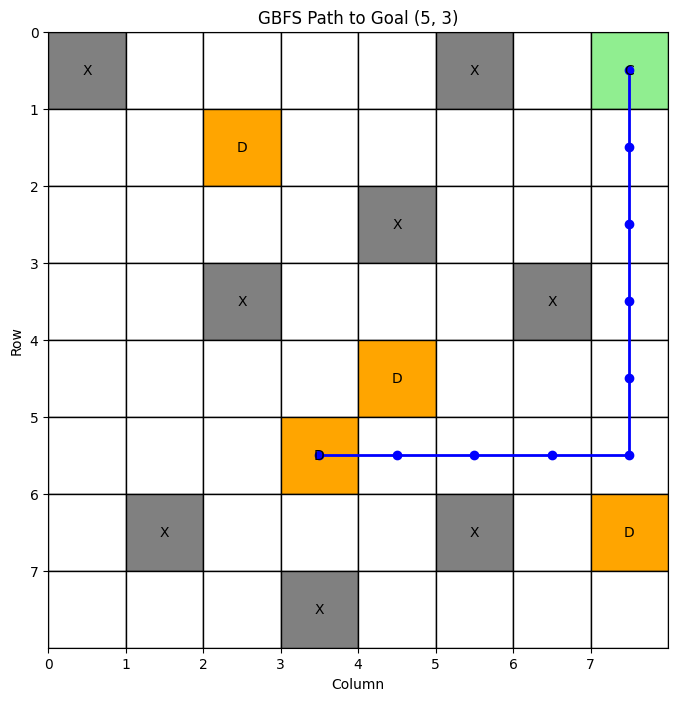

In [36]:
def display_gbfs_path(grid, path, goal):

    if path is None:
        print("No path available to visualize.")
        return

    display_grid(grid)

    rows = grid["rows"]
    cols = grid["cols"]

    fig, ax = plt.subplots(figsize=(8, 8))

    ax.set_xlim(0, cols)
    ax.set_ylim(rows, 0)

    for r in range(rows):
        for c in range(cols):

            color = "white"
            label = ""

            if (r, c) in grid["obstacles"]:
                color = "gray"
                label = "X"

            elif (r, c) in grid["dirty_locations"]:
                color = "orange"
                label = "D"

            elif (r, c) == grid["charging_station"]:
                color = "lightgreen"
                label = "C"

            rect = plt.Rectangle(
                (c, r), 1, 1,
                facecolor=color,
                edgecolor="black"
            )

            ax.add_patch(rect)

            if label:
                ax.text(
                    c + 0.5, r + 0.5, label,
                    ha="center", va="center"
                )

    # Draw GBFS path
    x = [col + 0.5 for row, col in path]
    y = [row + 0.5 for row, col in path]

    ax.plot(x, y, color="blue", linewidth=2, marker="o")

    ax.set_xticks(range(cols))
    ax.set_yticks(range(rows))
    ax.set_title(f"GBFS Path to Goal {goal}")
    ax.set_xlabel("Column")
    ax.set_ylabel("Row")

    plt.show()

start = grid["charging_station"]
goal = grid["dirty_locations"][0]

path, cost, expanded = greedy_best_first_search(
    start, goal, grid
)

display_gbfs_path(grid, path, goal)

### 11. Return Path to the Charging Station

After reaching a dirty location, the robot should be able to
return to its charging station.

In this test, GBFS is executed twice:
1. From the charging station to a selected dirty location.
2. From that dirty location back to the charging station.

The two paths are combined to represent a complete round trip.

The total trip cost is calculated by counting the movements
performed in both directions.

This test verifies that the robot can complete an individual
cleaning trip and return to its charging station.

In [37]:
start = grid["charging_station"]
goal = grid["dirty_locations"][0]

outward_path, outward_cost, outward_expanded = (
    greedy_best_first_search(start, goal, grid)
)

return_path, return_cost, return_expanded = (
    greedy_best_first_search(goal, start, grid)
)

if outward_path is not None and return_path is not None:

    complete_trip = outward_path + return_path[1:]

    print("Charging Station:", start)
    print("Dirty Location:", goal)

    print("\nOutward Path:", outward_path)
    print("Return Path:", return_path)

    print("\nComplete Trip:", complete_trip)

    print("Outward Cost:", outward_cost)
    print("Return Cost:", return_cost)

    print("Total Trip Cost:", path_cost(complete_trip))

    print(
        "Total Nodes Expanded:",
        outward_expanded + return_expanded
    )

else:
    print("Complete trip could not be generated.")

Charging Station: (0, 7)
Dirty Location: (5, 3)

Outward Path: [(0, 7), (1, 7), (2, 7), (3, 7), (4, 7), (5, 7), (5, 6), (5, 5), (5, 4), (5, 3)]
Return Path: [(5, 3), (4, 3), (3, 3), (2, 3), (1, 3), (1, 4), (1, 5), (1, 6), (0, 6), (0, 7)]

Complete Trip: [(0, 7), (1, 7), (2, 7), (3, 7), (4, 7), (5, 7), (5, 6), (5, 5), (5, 4), (5, 3), (4, 3), (3, 3), (2, 3), (1, 3), (1, 4), (1, 5), (1, 6), (0, 6), (0, 7)]
Outward Cost: 9
Return Cost: 9
Total Trip Cost: 18
Total Nodes Expanded: 20


### 12. Final Testing and Environment Validation

The final testing section verifies the correctness and consistency
of the environment configuration.

The Environment.txt file declares the total number of obstacles
and dirty locations. These declared counts must match the actual
coordinates provided in the file.

The program performs the following checks:

1. Verifies that the grid dimensions meet the minimum requirement.
2. Checks that at least six obstacles are provided.
3. Checks that at least four dirty locations are provided.
4. Verifies that declared counts match the actual coordinates.
5. Detects duplicate dirty locations.
6. Checks that all coordinates are within grid boundaries.
7. Prevents overlapping obstacles, dirty locations and
   the charging station.
8. Verifies that all dirty locations are reachable.

These checks help identify incorrect environment configurations
before running the search algorithms.

### 12.1 Storing Declared Environment Counts

The environment loader stores the declared number of obstacles
and dirty locations along with their actual coordinates.

These values are used during validation to identify mismatches
between the counts specified in Environment.txt and the
coordinates actually provided.

In [38]:
def parse_coordinates(text):
    coordinates = ast.literal_eval(text.strip())

    # Convert a single coordinate into a list
    if (
        isinstance(coordinates, tuple)
        and len(coordinates) == 2
        and all(isinstance(x, int) for x in coordinates)
    ):
        coordinates = [coordinates]

    return [tuple(point) for point in coordinates]


def load_environment(filename):

    with open(filename, "r") as file:
        lines = [line.strip() for line in file if line.strip()]

    # Read grid dimensions
    rows, cols = map(int, lines[0].split(","))

    # Read obstacle information
    obstacle_count = int(lines[1])
    obstacles = set(parse_coordinates(lines[2]))

    # Read dirty location information
    dirty_count = int(lines[3])
    dirty_locations = parse_coordinates(lines[4])

    # Read charging station
    charging_station = parse_coordinates(lines[5])[0]

    grid = {
        "rows": rows,
        "cols": cols,
        "obstacles": obstacles,
        "dirty_locations": dirty_locations,
        "charging_station": charging_station,

        "declared_obstacle_count": obstacle_count,
        "declared_dirty_count": dirty_count
    }

    return grid

### 12.2 Count Consistency Verification

This section compares the actual number of obstacle and dirty
location coordinates with the counts declared in Environment.txt.

If the values do not match, the validation function reports
an error and marks the environment as invalid.

For example, if the file declares eight obstacles but only
seven unique obstacle coordinates are provided, the program
will detect the inconsistency.

In [ ]:
def validate_environment(grid):

    rows = grid["rows"]
    cols = grid["cols"]
    obstacles = grid["obstacles"]
    dirty = grid["dirty_locations"]
    charging = grid["charging_station"]

    errors = []

    # Check grid dimensions
    if rows < 8 or cols < 8:
        errors.append("Grid must be at least 8x8.")

    # Check obstacle count
    if len(obstacles) < 6:
        errors.append("At least 6 obstacles are required.")

    # Check dirty locations
    if len(dirty) < 4:
        errors.append("At least 4 dirty locations are required.")

    # Check duplicate coordinates
    if len(dirty) != len(set(dirty)):
        errors.append("Duplicate dirty locations found.")

    # Verify declared counts against actual coordinates
    if len(obstacles) != grid["declared_obstacle_count"]:
        errors.append("Obstacle count does not match the file.")

    if len(dirty) != grid["declared_dirty_count"]:
        errors.append("Dirty location count does not match the file.")

    # Check coordinate boundaries
    all_positions = obstacles | set(dirty) | {charging}

    for r, c in all_positions:
        if not (0 <= r < rows and 0 <= c < cols):
            errors.append(f"Coordinate {(r, c)} is outside the grid.")

    # Check overlapping positions
    if obstacles.intersection(dirty):
        errors.append("An obstacle overlaps a dirty location.")

    if charging in obstacles:
        errors.append("Charging station overlaps an obstacle.")

    if charging in dirty:
        errors.append("Charging station overlaps a dirty location.")

    # Check every dirty location is reachable
    for location in dirty:
        if not is_reachable(charging, location, grid):
            errors.append(f"Dirty location {location} is unreachable.")

    if errors:
        print("Environment is INVALID:")
        for error in errors:
            print("-", error)
        return False

    print("Environment is VALID!")
    return True

### 12.3 Testing Environment Validation

After updating the environment loader and validation function,
the environment is loaded again and validated.

This test confirms whether the environment satisfies all
defined requirements before the final GBFS tests are performed.

In [39]:
grid = load_environment(filename)

environment_valid = validate_environment(grid)

if environment_valid:
    print("\nAll environment checks passed successfully.")
else:
    print("\nPlease correct the environment configuration.")

Environment is VALID!

All environment checks passed successfully.


### 12.4 Edge Case Testing: Same Starting and Goal Position

This test checks how GBFS behaves when the starting position
and goal position are identical.

Since the robot is already at the destination, the algorithm
should immediately return a path containing only the starting
position.

The expected path cost is zero because no movement is required.

In [40]:
start = grid["charging_station"]
goal = grid["charging_station"]

path, cost, expanded = greedy_best_first_search(
    start, goal, grid
)

print("Start:", start)
print("Goal:", goal)
print("Path:", path)
print("Path Cost:", cost)
print("Nodes Expanded:", expanded)

Start: (0, 7)
Goal: (0, 7)
Path: [(0, 7)]
Path Cost: 0
Nodes Expanded: 0


### 12.5 Edge Case Testing: Unreachable Goal

This test verifies that GBFS handles situations where a
destination cannot be reached.

A temporary test environment is created with obstacles
surrounding the goal position.

The algorithm should terminate and return None with an
infinite path cost when no valid route exists.

The original environment is not modified.

In [41]:
test_grid = {
    "rows": 8,
    "cols": 8,
    "obstacles": {
        (2, 3), (3, 2), (3, 4), (4, 3)
    },
    "dirty_locations": [(3, 3)],
    "charging_station": (0, 0),
    "declared_obstacle_count": 4,
    "declared_dirty_count": 1
}

start = (0, 0)
goal = (3, 3)

path, cost, expanded = greedy_best_first_search(
    start, goal, test_grid
)

print("Start:", start)
print("Goal:", goal)
print("Path:", path)
print("Path Cost:", cost)
print("Nodes Expanded:", expanded)

Start: (0, 0)
Goal: (3, 3)
Path: None
Path Cost: inf
Nodes Expanded: 59


### 12.6 Final GBFS Results Summary

The final testing phase summarizes the performance of the
Greedy Best-First Search algorithm.

The algorithm is evaluated using different dirty locations
and test scenarios.

The results include:
- Destination position.
- Whether a valid path was found.
- Total path cost.
- Number of nodes expanded.

The tests demonstrate the algorithm's ability to navigate
the environment, avoid obstacles and handle special cases.

In [42]:
if environment_valid:

    print("=" * 50)
    print("FINAL GBFS RESULTS")
    print("=" * 50)

    for index, goal in enumerate(grid["dirty_locations"]):

        path, cost, expanded = greedy_best_first_search(
            grid["charging_station"], goal, grid
        )

        print(f"\nDirty Location D{index + 1}: {goal}")

        if path is not None:
            print("Status: SUCCESS")
            print("Path:", path)
            print("Path Cost:", cost)
            print("Nodes Expanded:", expanded)

        else:
            print("Status: FAILURE")
            print("No valid path exists.")

else:
    print("GBFS testing skipped because the environment is invalid.")

FINAL GBFS RESULTS

Dirty Location D1: (5, 3)
Status: SUCCESS
Path: [(0, 7), (1, 7), (2, 7), (3, 7), (4, 7), (5, 7), (5, 6), (5, 5), (5, 4), (5, 3)]
Path Cost: 9
Nodes Expanded: 9

Dirty Location D2: (4, 4)
Status: SUCCESS
Path: [(0, 7), (1, 7), (2, 7), (3, 7), (4, 7), (4, 6), (4, 5), (4, 4)]
Path Cost: 7
Nodes Expanded: 7

Dirty Location D3: (1, 2)
Status: SUCCESS
Path: [(0, 7), (1, 7), (1, 6), (1, 5), (1, 4), (1, 3), (1, 2)]
Path Cost: 6
Nodes Expanded: 6

Dirty Location D4: (6, 7)
Status: SUCCESS
Path: [(0, 7), (1, 7), (2, 7), (3, 7), (4, 7), (5, 7), (6, 7)]
Path Cost: 6
Nodes Expanded: 6
